## CY 530 Port Scan Detection on CICIDS2017 and Independent Nmap Traffic

In [1]:
#Importing necessary libraries
import os
import pandas as pd
import numpy as np
import seaborn as sns
import missingno as msno
import matplotlib.pyplot as plt

In [2]:
#Loading data
file_name= "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv"
df = pd.read_csv(file_name, skipinitialspace=True, on_bad_lines='warn')


### Initial Data Exploration

In [3]:
print(df["Label"].value_counts())

Label
PortScan    158930
BENIGN      127537
Name: count, dtype: int64


In [4]:
print(df.shape)

(286467, 79)


In [5]:
print(df.columns.tolist())

['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count

In [6]:
df.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,22,1266342,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,22,1319353,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,22,160,1,1,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,22,1303488,41,42,2728,6634,456,0,66.536585,110.129945,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,35396,77,1,2,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [7]:
print("Dataset info:")
print(df.info())

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 286467 entries, 0 to 286466
Data columns (total 79 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Destination Port             286467 non-null  int64  
 1   Flow Duration                286467 non-null  int64  
 2   Total Fwd Packets            286467 non-null  int64  
 3   Total Backward Packets       286467 non-null  int64  
 4   Total Length of Fwd Packets  286467 non-null  int64  
 5   Total Length of Bwd Packets  286467 non-null  int64  
 6   Fwd Packet Length Max        286467 non-null  int64  
 7   Fwd Packet Length Min        286467 non-null  int64  
 8   Fwd Packet Length Mean       286467 non-null  float64
 9   Fwd Packet Length Std        286467 non-null  float64
 10  Bwd Packet Length Max        286467 non-null  int64  
 11  Bwd Packet Length Min        286467 non-null  int64  
 12  Bwd Packet Length Mean       286467 non-null

In [8]:
#Checking for null values
null_values = df.isnull().sum()
print("\nMissing Values:")
print(null_values[null_values > 0])


Missing Values:
Flow Bytes/s    15
dtype: int64


In [9]:
#summary statistics for columns in the dataset
print("\nSummary Statistics for columns:")
print(df.describe())


Summary Statistics for columns:
       Destination Port  Flow Duration  Total Fwd Packets  \
count     286467.000000   2.864670e+05      286467.000000   
mean        8044.876324   5.379331e+06           3.473283   
std        15378.583442   2.192364e+07          19.515131   
min            0.000000  -1.300000e+01           1.000000   
25%           80.000000   4.400000e+01           1.000000   
50%         1110.000000   6.500000e+01           1.000000   
75%         6881.000000   2.380600e+04           2.000000   
max        65389.000000   1.199999e+08        3119.000000   

       Total Backward Packets  Total Length of Fwd Packets  \
count           286467.000000                286467.000000   
mean                 3.520500                   233.407667   
std                 28.288916                  1865.523600   
min                  0.000000                     0.000000   
25%                  1.000000                     0.000000   
50%                  1.000000                

In [10]:
#checking duplicates
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

Number of duplicate rows: 72353


In [11]:
print("Infinite values by column:")
inf_counts = np.isinf(df.select_dtypes(include=np.number)).sum()
print(inf_counts[inf_counts > 0])

Infinite values by column:
Flow Bytes/s      356
Flow Packets/s    371
dtype: int64


In [12]:
numeric_df = df.select_dtypes(include=np.number)

print("Positive infinity:", np.isposinf(numeric_df).sum().sum())
print("Negative infinity:", np.isneginf(numeric_df).sum().sum())

Positive infinity: 727
Negative infinity: 0


### DATA CLEANING

In [13]:
# Replacing any infinite values (positive or negative) with NaN (not a number)
print(f'Initial missing values: {df.isna().sum().sum()}')

df.replace([np.inf, -np.inf], np.nan, inplace = True)

print(f'Missing values after processing infinite values: {df.isna().sum().sum()}')

Initial missing values: 15
Missing values after processing infinite values: 742


In [14]:
missing = df.isna().sum()
print(missing.loc[missing > 0])

Flow Bytes/s      371
Flow Packets/s    371
dtype: int64


In [15]:
duplicate_rows = df[df.duplicated(keep=False)]

print("Duplicate rows by label:")
print(duplicate_rows["Label"].value_counts())

Duplicate rows by label:
Label
PortScan    101501
BENIGN        6203
Name: count, dtype: int64


In [16]:
df_no_duplicates = df.drop_duplicates()

print("Original shape:", df.shape)
print("After removing duplicates:", df_no_duplicates.shape)

print("\nOriginal label counts:")
print(df["Label"].value_counts())

print("\nAfter removing duplicates:")
print(df_no_duplicates["Label"].value_counts())

Original shape: (286467, 79)
After removing duplicates: (214114, 79)

Original label counts:
Label
PortScan    158930
BENIGN      127537
Name: count, dtype: int64

After removing duplicates:
Label
BENIGN      123295
PortScan     90819
Name: count, dtype: int64


In [17]:
df = df_no_duplicates.copy()

print(df.shape)
print(df["Label"].value_counts())

(214114, 79)
Label
BENIGN      123295
PortScan     90819
Name: count, dtype: int64


In [18]:
missing_values = df.isnull().sum()

print("Missing values after deduplication:")
print(missing_values[missing_values > 0])

Missing values after deduplication:
Flow Bytes/s      337
Flow Packets/s    337
dtype: int64


In [19]:
print("Rows containing NaN:", df.isnull().any(axis=1).sum())

print("\nAffected rows by label:")
print(df.loc[df.isnull().any(axis=1), "Label"].value_counts())

Rows containing NaN: 337

Affected rows by label:
Label
BENIGN      212
PortScan    125
Name: count, dtype: int64


In [20]:
df = df.dropna().copy()

print("Cleaned dataset shape:", df.shape)

print("\nLabel distribution:")
print(df["Label"].value_counts())

print("\nRemaining missing values:", df.isnull().sum().sum())
print("Remaining infinite values:",
      np.isinf(df.select_dtypes(include=np.number)).sum().sum())

Cleaned dataset shape: (213777, 79)

Label distribution:
Label
BENIGN      123083
PortScan     90694
Name: count, dtype: int64

Remaining missing values: 0
Remaining infinite values: 0


### Preparing Labels and Training and Test Sets

In [21]:
X = df.drop(columns=["Label"])

y = df["Label"].map({
    "BENIGN": 0,
    "PortScan": 1
})

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nEncoded labels:")
print(y.value_counts())

Features shape: (213777, 78)
Target shape: (213777,)

Encoded labels:
Label
0    123083
1     90694
Name: count, dtype: int64


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training features: (171021, 78)
Testing features: (42756, 78)

Training labels:
Label
0    98466
1    72555
Name: count, dtype: int64

Testing labels:
Label
0    24617
1    18139
Name: count, dtype: int64


In [23]:
#Identifying constant features from training data only to avoid test-set leakage
constant_features = X_train.columns[X_train.nunique() <= 1]

print("Number of constant features:", len(constant_features))
print("\nConstant features:")
print(constant_features.tolist())

Number of constant features: 10

Constant features:
['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


In [24]:
X_train = X_train.drop(columns=constant_features)
X_test = X_test.drop(columns=constant_features)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nRemaining features:", X_train.shape[1])

Training features: (171021, 68)
Testing features: (42756, 68)

Remaining features: 68


### Train Decision Tree and Random Forest

In [25]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree training completed!")
print("Tree depth:", dt_model.get_depth())
print("Number of leaves:", dt_model.get_n_leaves())

Decision Tree training completed!
Tree depth: 11
Number of leaves: 42


In [26]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")
print("Number of trees:", len(rf_model.estimators_))

Random Forest training completed!
Number of trees: 100


### Evaluation on the CICIDS2017 Test set

In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predicting labels for the testing dataset
y_pred_dt = dt_model.predict(X_test)

# Calculating evaluation metrics
print("Decision Tree Evaluation")
print("------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1-score:", f1_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["BENIGN", "PortScan"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Decision Tree Evaluation
------------------------
Accuracy: 0.9999298344092057
Precision: 1.0
Recall: 0.9998346105077457
F1-score: 0.9999172984148863

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     24617
    PortScan       1.00      1.00      1.00     18139

    accuracy                           1.00     42756
   macro avg       1.00      1.00      1.00     42756
weighted avg       1.00      1.00      1.00     42756


Confusion Matrix:
[[24617     0]
 [    3 18136]]


In [28]:
# Predicting using Random Forest
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Evaluation")
print("------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-score:", f1_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["BENIGN", "PortScan"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Evaluation
------------------------
Accuracy: 0.999906445878941
Precision: 1.0
Recall: 0.9997794806769943
F1-score: 0.9998897281799636

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     24617
    PortScan       1.00      1.00      1.00     18139

    accuracy                           1.00     42756
   macro avg       1.00      1.00      1.00     42756
weighted avg       1.00      1.00      1.00     42756


Confusion Matrix:
[[24617     0]
 [    4 18135]]


### Model Performance Table

In [33]:
dt_pred = dt_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

performance_table = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Decision Tree": [
        accuracy_score(y_test, dt_pred),
        precision_score(y_test, dt_pred),
        recall_score(y_test, dt_pred),
        f1_score(y_test, dt_pred)
    ],
    "Random Forest": [
        accuracy_score(y_test, rf_pred),
        precision_score(y_test, rf_pred),
        recall_score(y_test, rf_pred),
        f1_score(y_test, rf_pred)
    ]
})

for col in ["Decision Tree", "Random Forest"]:
    performance_table[col] = performance_table[col].map(
        lambda x: f"{x * 100:.3f}%"
    )

display(performance_table)
performance_table.to_csv("table1_model_performance.csv", index=False)

,Metric,Decision Tree,Random Forest
0,Accuracy,99.993%,99.991%
1,Precision,100.000%,100.000%
2,Recall,99.983%,99.978%
3,F1-score,99.992%,99.989%


##**Analysis**

In [29]:
dt_importance = pd.Series(
    dt_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 10 Decision Tree Features:")
print(dt_importance.head(10))

Top 10 Decision Tree Features:
Total Length of Fwd Packets    0.798800
Flow Bytes/s                   0.171954
Min Packet Length              0.007523
Init_Win_bytes_forward         0.005397
Packet Length Mean             0.004868
Bwd Packets/s                  0.003445
ACK Flag Count                 0.003178
Packet Length Variance         0.001277
Flow IAT Std                   0.001150
Bwd IAT Max                    0.000588
dtype: float64


In [30]:
rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 10 Random Forest Features:")
print(rf_importance.head(10))

Top 10 Random Forest Features:
Avg Fwd Segment Size           0.119882
Subflow Fwd Bytes              0.089413
Packet Length Mean             0.081025
Fwd Packet Length Mean         0.074962
Average Packet Size            0.062434
Fwd Packet Length Max          0.055840
Total Length of Fwd Packets    0.049829
PSH Flag Count                 0.044422
Max Packet Length              0.043317
Bwd Packets/s                  0.039384
dtype: float64


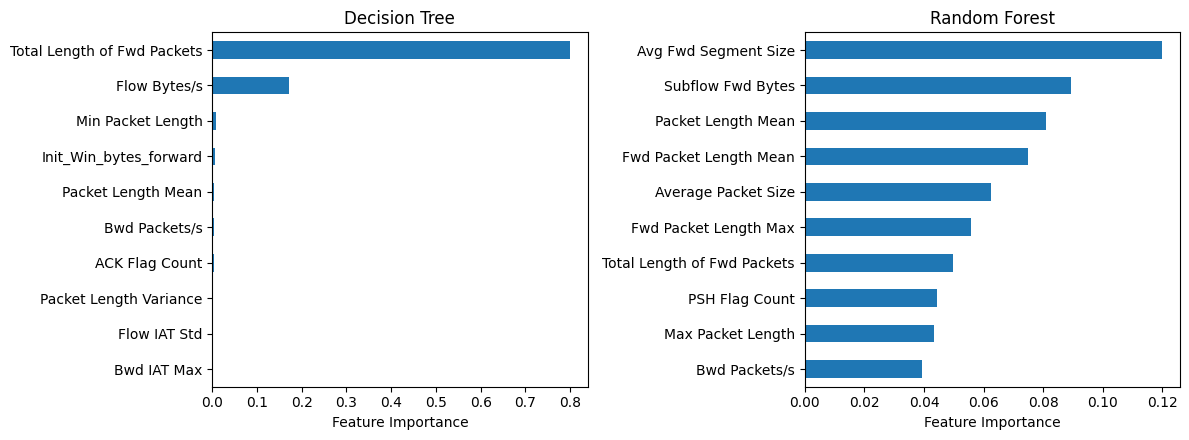

In [32]:
# Decision Tree
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
dt_importance.head(10).sort_values().plot(
    kind="barh",
    ax=axes[0],
    title="Decision Tree"
)
axes[0].set_xlabel("Feature Importance")

# Random Forest
rf_importance.head(10).sort_values().plot(
    kind="barh",
    ax=axes[1],
    title="Random Forest"
)
axes[1].set_xlabel("Feature Importance")

plt.tight_layout()
plt.savefig("feature_importance_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import joblib
# Saving both trained models
joblib.dump(dt_model, "decision_tree_model.pkl")
joblib.dump(rf_model, "random_forest_model.pkl")

# Saving the exact feature names and order
joblib.dump(X_train.columns.tolist(), "feature_columns.pkl")

print("Models and feature list saved successfully!")

Models and feature list saved successfully!


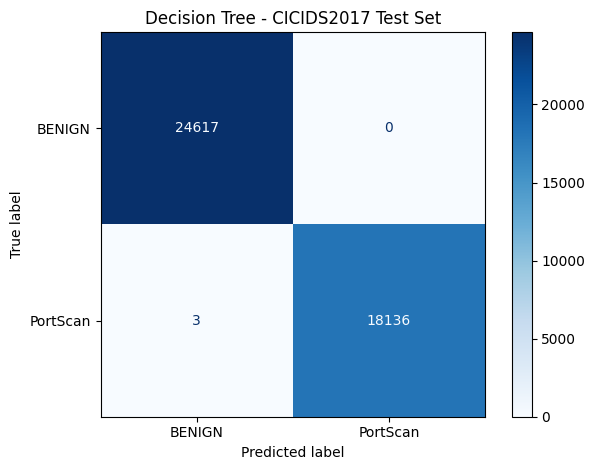

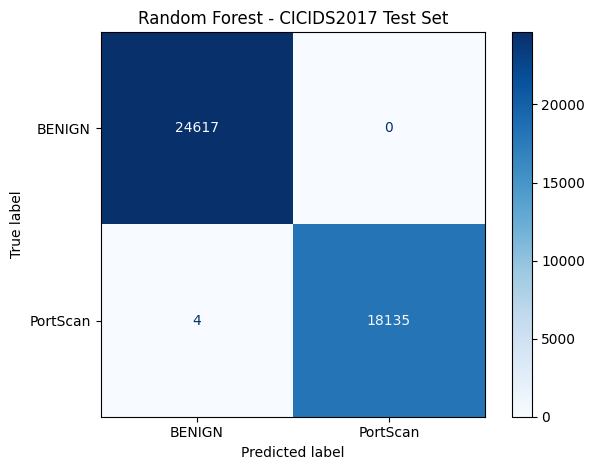

Evaluation results and figures saved!
           Model  Accuracy  Precision    Recall  F1-score
0  Decision Tree  0.999930        1.0  0.999835  0.999917
1  Random Forest  0.999906        1.0  0.999779  0.999890


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# Saving comparison metrics
results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ]
})

results.to_csv("cicids2017_model_comparison.csv", index=False)

# Saving separate confusion matrix figures
for model_name, predictions, filename in [
    ("Decision Tree", y_pred_dt, "dt_confusion_matrix.png"),
    ("Random Forest", y_pred_rf, "rf_confusion_matrix.png")
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["BENIGN", "PortScan"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"{model_name} - CICIDS2017 Test Set")
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

print("Evaluation results and figures saved!")
print(results)

In [ ]:
print("Number of training features:", len(X_train.columns))

for i, feature in enumerate(X_train.columns, 1):
    print(f"{i:02d}. {feature}")

Number of training features: 68
01. Destination Port
02. Flow Duration
03. Total Fwd Packets
04. Total Backward Packets
05. Total Length of Fwd Packets
06. Total Length of Bwd Packets
07. Fwd Packet Length Max
08. Fwd Packet Length Min
09. Fwd Packet Length Mean
10. Fwd Packet Length Std
11. Bwd Packet Length Max
12. Bwd Packet Length Min
13. Bwd Packet Length Mean
14. Bwd Packet Length Std
15. Flow Bytes/s
16. Flow Packets/s
17. Flow IAT Mean
18. Flow IAT Std
19. Flow IAT Max
20. Flow IAT Min
21. Fwd IAT Total
22. Fwd IAT Mean
23. Fwd IAT Std
24. Fwd IAT Max
25. Fwd IAT Min
26. Bwd IAT Total
27. Bwd IAT Mean
28. Bwd IAT Std
29. Bwd IAT Max
30. Bwd IAT Min
31. Fwd PSH Flags
32. Fwd Header Length
33. Bwd Header Length
34. Fwd Packets/s
35. Bwd Packets/s
36. Min Packet Length
37. Max Packet Length
38. Packet Length Mean
39. Packet Length Std
40. Packet Length Variance
41. FIN Flag Count
42. SYN Flag Count
43. RST Flag Count
44. PSH Flag Count
45. ACK Flag Count
46. URG Flag Count
47. ECE

In [ ]:
import json

feature_columns = X_train.columns.tolist()

with open("training_features.json", "w") as f:
    json.dump(feature_columns, f, indent=2)

print(f"Saved {len(feature_columns)} features")
from google.colab import files
files.download("training_features.json")

Saved 68 features


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Inspecting CICFlowMeter Schema

In [ ]:
#Optional schema diagnostic using test.pcap_Flow.csv (not used in final results).
with open("training_features.json", "r") as f:
    training_features = json.load(f)

external_df = pd.read_csv("test.pcap_Flow.csv")

print("Training features:", len(training_features))
print("CICFlowMeter columns:", len(external_df.columns))
print("External CSV shape:", external_df.shape)

Training features: 68
CICFlowMeter columns: 84
External CSV shape: (1, 84)


In [ ]:
external_columns = external_df.columns.tolist()

matching = [
    col for col in training_features
    if col in external_columns
]

missing = [
    col for col in training_features
    if col not in external_columns
]

print("Exact matches:", len(matching))
print("Missing or differently named:", len(missing))

print("\n--- Missing or differently named features ---")
for i, col in enumerate(missing, 1):
    print(f"{i:02d}. {col}")

Exact matches: 54
Missing or differently named: 14

--- Missing or differently named features ---
01. Destination Port
02. Total Fwd Packets
03. Total Backward Packets
04. Total Length of Fwd Packets
05. Total Length of Bwd Packets
06. Min Packet Length
07. Max Packet Length
08. Avg Fwd Segment Size
09. Avg Bwd Segment Size
10. Fwd Header Length.1
11. Init_Win_bytes_forward
12. Init_Win_bytes_backward
13. act_data_pkt_fwd
14. min_seg_size_forward


In [ ]:
 extra_columns = [
    col for col in external_df.columns
    if col not in training_features
]

print("CICFlowMeter columns without exact matches:")
for i, col in enumerate(extra_columns, 1):
    print(f"{i:02d}. {col}")

CICFlowMeter columns without exact matches:
01. Flow ID
02. Src IP
03. Src Port
04. Dst IP
05. Dst Port
06. Protocol
07. Timestamp
08. Total Fwd Packet
09. Total Bwd packets
10. Total Length of Fwd Packet
11. Total Length of Bwd Packet
12. Bwd PSH Flags
13. Fwd URG Flags
14. Bwd URG Flags
15. Packet Length Min
16. Packet Length Max
17. CWR Flag Count
18. Fwd Segment Size Avg
19. Bwd Segment Size Avg
20. Fwd Bytes/Bulk Avg
21. Fwd Packet/Bulk Avg
22. Fwd Bulk Rate Avg
23. Bwd Bytes/Bulk Avg
24. Bwd Packet/Bulk Avg
25. Bwd Bulk Rate Avg
26. FWD Init Win Bytes
27. Bwd Init Win Bytes
28. Fwd Act Data Pkts
29. Fwd Seg Size Min
30. Label


In [ ]:
print("Original feature:")
print(X_train["Fwd Header Length"].head(10))

print("\nDuplicate-named feature:")
print(X_train["Fwd Header Length.1"].head(10))

print("\nAre all values identical?")
print(
    X_train["Fwd Header Length"].equals(
        X_train["Fwd Header Length.1"]
    )
)

Original feature:
263387     60
140702     24
74918      40
21782      20
272568     40
285932    296
32565      92
126736     24
5486       72
178409     40
Name: Fwd Header Length, dtype: int64

Duplicate-named feature:
263387     60
140702     24
74918      40
21782      20
272568     40
285932    296
32565      92
126736     24
5486       72
178409     40
Name: Fwd Header Length.1, dtype: int64

Are all values identical?
True


In [ ]:
#Mapping external CICFlowMeter naming differences to training feature names
column_mapping = {
    "Dst Port": "Destination Port",
    "Total Fwd Packet": "Total Fwd Packets",
    "Total Bwd packets": "Total Backward Packets",
    "Total Length of Fwd Packet": "Total Length of Fwd Packets",
    "Total Length of Bwd Packet": "Total Length of Bwd Packets",
    "Packet Length Min": "Min Packet Length",
    "Packet Length Max": "Max Packet Length",
    "Fwd Segment Size Avg": "Avg Fwd Segment Size",
    "Bwd Segment Size Avg": "Avg Bwd Segment Size",
    "FWD Init Win Bytes": "Init_Win_bytes_forward",
    "Bwd Init Win Bytes": "Init_Win_bytes_backward",
    "Fwd Act Data Pkts": "act_data_pkt_fwd",
    "Fwd Seg Size Min": "min_seg_size_forward"
}

# Renaming the CICFlowMeter columns
aligned_df = external_df.rename(columns=column_mapping).copy()

# Reproducing the duplicate feature from CICIDS2017
aligned_df["Fwd Header Length.1"] = aligned_df["Fwd Header Length"]

# Checking that all 68 features are available
missing_features = [
    col for col in training_features
    if col not in aligned_df.columns
]

if missing_features:
    raise ValueError(f"Missing features: {missing_features}")

# Selecting features in the exact training order
X_external = aligned_df[training_features].copy()

print("Aligned dataset shape:", X_external.shape)
print("All feature names match:",
      X_external.columns.tolist() == training_features)

Aligned dataset shape: (1, 68)
All feature names match: True


In [ ]:
# Converting all features to numeric values
X_external = X_external.apply(
    pd.to_numeric, errors="coerce"
)

# Counting invalid values
nan_count = X_external.isna().sum().sum()

positive_inf = np.isposinf(X_external.to_numpy()).sum()
negative_inf = np.isneginf(X_external.to_numpy()).sum()

print("Dataset shape:", X_external.shape)
print("Missing/NaN values:", nan_count)
print("Positive infinity:", positive_inf)
print("Negative infinity:", negative_inf)

Dataset shape: (1, 68)
Missing/NaN values: 0
Positive infinity: 0
Negative infinity: 0


In [ ]:
print("Decision Tree available:", "dt_model" in globals())
print("Random Forest available:", "rf_model" in globals())
print("Training features available:", "X_train" in globals())

Decision Tree available: True
Random Forest available: True
Training features available: True


In [ ]:
training_features = X_train.columns.tolist()

print("Number of training features:", len(training_features))
print("Decision Tree expects:", dt_model.n_features_in_)
print("Random Forest expects:", rf_model.n_features_in_)
print("First 5 features:", training_features[:5])

Number of training features: 68
Decision Tree expects: 68
Random Forest expects: 68
First 5 features: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets']


### Testing the model with external self-generated data

In [ ]:
# These CSV files must first be generated from the independent VM lab captures.
syn_df = pd.read_csv("syn_scan.pcap_Flow.csv")
fin_df = pd.read_csv("fin_scan.pcap_Flow.csv")
udp_df = pd.read_csv("udp_scan.pcap_Flow.csv")

print("SYN:", syn_df.shape)
print("FIN:", fin_df.shape)
print("UDP:", udp_df.shape)

print("\nSame columns across all files:",
      list(syn_df.columns) == list(fin_df.columns) == list(udp_df.columns))

SYN: (1002, 84)
FIN: (1005, 84)
UDP: (202, 84)

Same columns across all files: True


### Filtering and Aligning External Features

In [ ]:
# Keep only flows from the scanner to the target with the expected protocol.
scanner_ip = "10.12.1.10"
target_ip = "10.12.1.20"

def filter_scan(df, protocol):
    return df[
        (df["Src IP"] == scanner_ip) &
        (df["Dst IP"] == target_ip) &
        (df["Protocol"] == protocol)
    ].copy()

syn_clean = filter_scan(syn_df, 6)
fin_clean = filter_scan(fin_df, 6)
udp_clean = filter_scan(udp_df, 17)

print("SYN:", syn_clean.shape)
print("FIN:", fin_clean.shape)
print("UDP:", udp_clean.shape)

print("Total candidate flows:",
      len(syn_clean) + len(fin_clean) + len(udp_clean))

SYN: (1000, 84)
FIN: (1001, 84)
UDP: (193, 84)
Total candidate flows: 2194


In [ ]:
missing_features = [
    col for col in training_features
    if col not in syn_clean.columns
]

print("Training features:", len(training_features))
print("Features not directly matching:", len(missing_features))

print("\nUnmatched training features:")
for col in missing_features:
    print(repr(col))

Training features: 68
Features not directly matching: 14

Unmatched training features:
'Destination Port'
'Total Fwd Packets'
'Total Backward Packets'
'Total Length of Fwd Packets'
'Total Length of Bwd Packets'
'Min Packet Length'
'Max Packet Length'
'Avg Fwd Segment Size'
'Avg Bwd Segment Size'
'Fwd Header Length.1'
'Init_Win_bytes_forward'
'Init_Win_bytes_backward'
'act_data_pkt_fwd'
'min_seg_size_forward'


In [ ]:
print("CICFlowMeter columns:\n")

for col in syn_clean.columns:
    print(repr(col))

CICFlowMeter columns:

'Flow ID'
'Src IP'
'Src Port'
'Dst IP'
'Dst Port'
'Protocol'
'Timestamp'
'Flow Duration'
'Total Fwd Packet'
'Total Bwd packets'
'Total Length of Fwd Packet'
'Total Length of Bwd Packet'
'Fwd Packet Length Max'
'Fwd Packet Length Min'
'Fwd Packet Length Mean'
'Fwd Packet Length Std'
'Bwd Packet Length Max'
'Bwd Packet Length Min'
'Bwd Packet Length Mean'
'Bwd Packet Length Std'
'Flow Bytes/s'
'Flow Packets/s'
'Flow IAT Mean'
'Flow IAT Std'
'Flow IAT Max'
'Flow IAT Min'
'Fwd IAT Total'
'Fwd IAT Mean'
'Fwd IAT Std'
'Fwd IAT Max'
'Fwd IAT Min'
'Bwd IAT Total'
'Bwd IAT Mean'
'Bwd IAT Std'
'Bwd IAT Max'
'Bwd IAT Min'
'Fwd PSH Flags'
'Bwd PSH Flags'
'Fwd URG Flags'
'Bwd URG Flags'
'Fwd Header Length'
'Bwd Header Length'
'Fwd Packets/s'
'Bwd Packets/s'
'Packet Length Min'
'Packet Length Max'
'Packet Length Mean'
'Packet Length Std'
'Packet Length Variance'
'FIN Flag Count'
'SYN Flag Count'
'RST Flag Count'
'PSH Flag Count'
'ACK Flag Count'
'URG Flag Count'
'CWR Flag Coun

In [ ]:
# Reconciling the external CICFlowMeter schema with the 68 training features.
feature_mapping = {
    "Dst Port": "Destination Port",
    "Total Fwd Packet": "Total Fwd Packets",
    "Total Bwd packets": "Total Backward Packets",
    "Total Length of Fwd Packet": "Total Length of Fwd Packets",
    "Total Length of Bwd Packet": "Total Length of Bwd Packets",
    "Packet Length Min": "Min Packet Length",
    "Packet Length Max": "Max Packet Length",
    "Fwd Segment Size Avg": "Avg Fwd Segment Size",
    "Bwd Segment Size Avg": "Avg Bwd Segment Size",
    "FWD Init Win Bytes": "Init_Win_bytes_forward",
    "Bwd Init Win Bytes": "Init_Win_bytes_backward",
    "Fwd Act Data Pkts": "act_data_pkt_fwd",
    "Fwd Seg Size Min": "min_seg_size_forward"
}

def align_features(df):
    aligned = df.rename(columns=feature_mapping).copy()

    # CICIDS2017 contains a duplicate forward-header-length feature.
    aligned["Fwd Header Length.1"] = aligned["Fwd Header Length"]

    missing = [
        col for col in training_features
        if col not in aligned.columns
    ]

    if missing:
        raise ValueError(f"Missing features: {missing}")

    return aligned[training_features].copy()

X_syn = align_features(syn_clean)
X_fin = align_features(fin_clean)
X_udp = align_features(udp_clean)

print("SYN:", X_syn.shape)
print("FIN:", X_fin.shape)
print("UDP:", X_udp.shape)

print("\nAll feature orders match training:",
      all(
          list(X.columns) == training_features
          for X in [X_syn, X_fin, X_udp]
      ))

SYN: (1000, 68)
FIN: (1001, 68)
UDP: (193, 68)

All feature orders match training: True


### Checking external data quality

In [ ]:
for name, X in [
    ("SYN", X_syn),
    ("FIN", X_fin),
    ("UDP", X_udp)
]:
    numeric = X.apply(pd.to_numeric, errors="coerce")

    missing = numeric.isna().sum().sum()
    infinite = np.isinf(numeric.to_numpy()).sum()

    print(f"\n{name} scan:")
    print("Shape:", numeric.shape)
    print("Missing/Non-numeric values:", missing)
    print("Infinite values:", infinite)

    inf_columns = pd.Series(
        np.isinf(numeric.to_numpy()).sum(axis=0),
        index=numeric.columns
    )
    print("Columns containing infinity:")
    print(inf_columns[inf_columns > 0].to_dict())


SYN scan:
Shape: (1000, 68)
Missing/Non-numeric values: 0
Infinite values: 0
Columns containing infinity:
{}

FIN scan:
Shape: (1001, 68)
Missing/Non-numeric values: 10
Infinite values: 2
Columns containing infinity:
{'Flow Packets/s': 2}

UDP scan:
Shape: (193, 68)
Missing/Non-numeric values: 921
Infinite values: 201
Columns containing infinity:
{'Flow Bytes/s': 14, 'Flow Packets/s': 187}


In [ ]:
for name, X in [("FIN", X_fin), ("UDP", X_udp)]:
    numeric = X.apply(pd.to_numeric, errors="coerce")

    missing_by_column = numeric.isna().sum()
    missing_by_column = missing_by_column[
        missing_by_column > 0
    ].sort_values(ascending=False)

    print(f"\n{name} — columns with missing/non-numeric values:")
    print(missing_by_column.to_string())


FIN — columns with missing/non-numeric values:
Flow Bytes/s     2
Flow IAT Mean    2
Flow IAT Std     2
Flow IAT Max     2
Flow IAT Min     2

UDP — columns with missing/non-numeric values:
Flow IAT Mean    187
Flow IAT Max     187
Flow IAT Std     187
Flow IAT Min     187
Flow Bytes/s     173


In [ ]:
print("Training rows:", len(X_train))
print("Training missing values:", X_train.isna().sum().sum())
print("Training infinite values:",
      np.isinf(X_train.to_numpy()).sum())

print("\nTraining values for affected features:")
print(
    X_train[
        ["Flow Bytes/s", "Flow Packets/s",
         "Flow IAT Mean", "Flow IAT Std",
         "Flow IAT Max", "Flow IAT Min"]
    ].describe().round(2)
)

Training rows: 171021
Training missing values: 0
Training infinite values: 0

Training values for affected features:
       Flow Bytes/s  Flow Packets/s  Flow IAT Mean  Flow IAT Std  \
count  1.710210e+05       171021.00      171021.00     171021.00   
mean   1.368859e+06        61541.31      462772.81     900160.61   
std    2.998220e+07       203846.88     2467367.01    4437479.94   
min   -1.200000e+07     -2000000.00         -13.00          0.00   
25%    3.393260e+03           65.53          47.67          0.00   
50%    9.756098e+04        22222.22          76.00          0.00   
75%    2.222222e+05        41666.67       23595.00      13681.72   
max    2.070000e+09      3000000.00    98100000.00   84800000.00   

       Flow IAT Max  Flow IAT Min  
count  1.710210e+05     171021.00  
mean   2.439763e+06      14978.71  
std    1.036899e+07     426957.83  
min   -1.300000e+01        -13.00  
25%    4.800000e+01          3.00  
50%    1.050000e+02         42.00  
75%    4.742200e+0

In [ ]:
# Reporting how many rows have finite values in every required feature.
for name, X in [("SYN", X_syn), ("FIN", X_fin), ("UDP", X_udp)]:
    numeric = X.apply(pd.to_numeric, errors="coerce")

    valid_mask = np.isfinite(numeric.to_numpy()).all(axis=1)

    print(f"{name}:")
    print("  Total flows:", len(X))
    print("  Fully finite flows:", valid_mask.sum())
    print("  Excluded flows:", (~valid_mask).sum())

SYN:
  Total flows: 1000
  Fully finite flows: 1000
  Excluded flows: 0
FIN:
  Total flows: 1001
  Fully finite flows: 999
  Excluded flows: 2
UDP:
  Total flows: 193
  Fully finite flows: 6
  Excluded flows: 187


### Testing Trained Models on External TCP scans

In [ ]:
for name, X in [("SYN", X_syn), ("FIN", X_fin)]:
    X_numeric = X.apply(pd.to_numeric, errors="coerce")
    X_valid = X_numeric.loc[
        np.isfinite(X_numeric.to_numpy()).all(axis=1)
    ]

    dt_predictions = dt_model.predict(X_valid)
    rf_predictions = rf_model.predict(X_valid)

    print(f"\n{name} scan ({len(X_valid)} valid flows)")
    print("Decision Tree predictions:")
    print(pd.Series(dt_predictions).value_counts())

    print("Random Forest predictions:")
    print(pd.Series(rf_predictions).value_counts())


SYN scan (1000 valid flows)
Decision Tree predictions:
0    1000
Name: count, dtype: int64
Random Forest predictions:
0    1000
Name: count, dtype: int64

FIN scan (999 valid flows)
Decision Tree predictions:
0    999
Name: count, dtype: int64
Random Forest predictions:
0    999
Name: count, dtype: int64


In [ ]:
print("Decision Tree classes:", dt_model.classes_)
print("Random Forest classes:", rf_model.classes_)

print("\nOriginal training labels:")
print(y_train.value_counts())

Decision Tree classes: [0 1]
Random Forest classes: [0 1]

Original training labels:
Label
0    98466
1    72555
Name: count, dtype: int64


### Investigate Prediction Errors

In [ ]:
features = [
    "Destination Port",
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Packets/s",
    "SYN Flag Count"
]

print("Training PortScan flows:")
print(X_train.loc[y_train == 1, features].median())

print("\nExternal SYN scan flows:")
print(X_syn[features].median())

Training PortScan flows:
Destination Port           3546.0
Flow Duration                50.0
Total Fwd Packets             1.0
Total Backward Packets        1.0
Flow Packets/s            40000.0
SYN Flag Count                0.0
dtype: float64

External SYN scan flows:
Destination Port          3720.000000
Flow Duration              449.000000
Total Fwd Packets            1.000000
Total Backward Packets       1.000000
Flow Packets/s            4454.342984
SYN Flag Count               1.000000
dtype: float64


In [ ]:
importance = pd.DataFrame({
    "Feature": training_features,
    "Decision Tree": dt_model.feature_importances_,
    "Random Forest": rf_model.feature_importances_
})

print("Top 10 Decision Tree features:")
print(
    importance.nlargest(10, "Decision Tree")
    [["Feature", "Decision Tree"]]
    .to_string(index=False)
)

print("\nTop 10 Random Forest features:")
print(
    importance.nlargest(10, "Random Forest")
    [["Feature", "Random Forest"]]
    .to_string(index=False)
)

Top 10 Decision Tree features:
                    Feature  Decision Tree
Total Length of Fwd Packets       0.798800
               Flow Bytes/s       0.171954
          Min Packet Length       0.007523
     Init_Win_bytes_forward       0.005397
         Packet Length Mean       0.004868
              Bwd Packets/s       0.003445
             ACK Flag Count       0.003178
     Packet Length Variance       0.001277
               Flow IAT Std       0.001150
                Bwd IAT Max       0.000588

Top 10 Random Forest features:
                    Feature  Random Forest
       Avg Fwd Segment Size       0.119882
          Subflow Fwd Bytes       0.089413
         Packet Length Mean       0.081025
     Fwd Packet Length Mean       0.074962
        Average Packet Size       0.062434
      Fwd Packet Length Max       0.055840
Total Length of Fwd Packets       0.049829
             PSH Flag Count       0.044422
          Max Packet Length       0.043317
              Bwd Packets/s       

In [ ]:
feature = "Total Length of Fwd Packets"

for name, X in [
    ("Training BENIGN", X_train.loc[y_train == 0]),
    ("Training PortScan", X_train.loc[y_train == 1]),
    ("External SYN", X_syn),
    ("External FIN", X_fin)
]:
    print(name)
    print(X[feature].describe()[["min", "25%", "50%", "75%", "max"]])
    print()

Training BENIGN
min         0.0
25%        31.0
50%        70.0
75%       164.0
max    232349.0
Name: Total Length of Fwd Packets, dtype: float64

Training PortScan
min      0.0
25%      0.0
50%      0.0
75%      2.0
max    703.0
Name: Total Length of Fwd Packets, dtype: float64

External SYN
min    0.0
25%    0.0
50%    0.0
75%    0.0
max    0.0
Name: Total Length of Fwd Packets, dtype: float64

External FIN
min    0.0
25%    0.0
50%    0.0
75%    0.0
max    0.0
Name: Total Length of Fwd Packets, dtype: float64



In [ ]:
from sklearn.tree import export_text

print(
    export_text(
        dt_model,
        feature_names=training_features,
        max_depth=2
    )
)

|--- Total Length of Fwd Packets <= 3.00
|   |--- Flow Bytes/s <= 2223.21
|   |   |--- Init_Win_bytes_forward <= 29080.00
|   |   |   |--- truncated branch of depth 9
|   |   |--- Init_Win_bytes_forward >  29080.00
|   |   |   |--- truncated branch of depth 5
|   |--- Flow Bytes/s >  2223.21
|   |   |--- ACK Flag Count <= 0.50
|   |   |   |--- class: 1
|   |   |--- ACK Flag Count >  0.50
|   |   |   |--- class: 0
|--- Total Length of Fwd Packets >  3.00
|   |--- Packet Length Mean <= 3.06
|   |   |--- Min Packet Length <= 1.00
|   |   |   |--- truncated branch of depth 3
|   |   |--- Min Packet Length >  1.00
|   |   |   |--- class: 1
|   |--- Packet Length Mean >  3.06
|   |   |--- Packet Length Variance <= 2698568.50
|   |   |   |--- truncated branch of depth 7
|   |   |--- Packet Length Variance >  2698568.50
|   |   |   |--- truncated branch of depth 2



In [ ]:
feature = "Total Length of Fwd Packets"

for label, name in [(0, "BENIGN"), (1, "PortScan")]:
    subset = X_train.loc[y_train == label]

    zero_count = (subset[feature] == 0).sum()

    print(f"{name}:")
    print("Total training flows:", len(subset))
    print("Flows with value 0:", zero_count)
    print("Percentage:", round(zero_count / len(subset) * 100, 2), "%")
    print()

BENIGN:
Total training flows: 98466
Flows with value 0: 8907
Percentage: 9.05 %

PortScan:
Total training flows: 72555
Flows with value 0: 36470
Percentage: 50.27 %



### Artificially changing feature to inspect Model Sensitivity

In [ ]:
X_syn_test = X_syn.copy()

# Counterfactual diagnostic only — not real scan data
X_syn_test["Total Length of Fwd Packets"] = 2

print("Original SYN predictions:")
print(pd.Series(dt_model.predict(X_syn)).value_counts())

print("\nCounterfactual SYN predictions:")
print(pd.Series(dt_model.predict(X_syn_test)).value_counts())

Original SYN predictions:
0    1000
Name: count, dtype: int64

Counterfactual SYN predictions:
0    1000
Name: count, dtype: int64


In [ ]:
print("Original Random Forest predictions:")
print(pd.Series(rf_model.predict(X_syn)).value_counts())

print("\nCounterfactual Random Forest predictions:")
print(pd.Series(rf_model.predict(X_syn_test)).value_counts())

Original Random Forest predictions:
0    1000
Name: count, dtype: int64

Counterfactual Random Forest predictions:
0    1000
Name: count, dtype: int64


### Additional Check for Consistency

In [ ]:
train_rows = pd.MultiIndex.from_frame(X_train)
test_rows = pd.MultiIndex.from_frame(X_test)

overlap = test_rows.isin(train_rows)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Test rows also found in training:", overlap.sum())
print("Overlap percentage:", round(overlap.mean() * 100, 2), "%")

Training rows: 171021
Testing rows: 42756
Test rows also found in training: 0
Overlap percentage: 0.0 %


In [ ]:
print("Current dataset shape:", df.shape)
print("\nOriginal label distribution:")
print(df["Label"].value_counts())

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Current dataset shape: (213777, 79)

Original label distribution:
Label
BENIGN      123083
PortScan     90694
Name: count, dtype: int64

Training shape: (171021, 68)
Testing shape: (42756, 68)
